In [ ]:
# ===============================
# import libraries
# ===============================
import numpy as np
import pandas as pd
from pathlib import Path
import chartgazing as cg

cg.set_size("4:5")

In [48]:
# ===============================
# import data
# ===============================

# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# additional data on each set
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
pokemon_all = pokemon_all.merge(sets_df, on="set_slug", how="left")

In [ ]:
# ===============================
# clean data
# ===============================
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10


for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [50]:
pokemon_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 13124130 entries, 0 to 13124129
Data columns (total 13 columns):
 #   Column        Dtype         
---  ------        -----         
 0   grade         category      
 1   date          datetime64[us]
 2   price         float64       
 3   set_slug      category      
 4   product_id    str           
 5   name          category      
 6   variant       category      
 7   number        str           
 8   set_name      category      
 9   language      category      
 10  release_date  datetime64[us]
 11  promo         bool          
 12  decade        int32         
dtypes: bool(1), category(6), datetime64[us](2), float64(1), int32(1), str(2)
memory usage: 797.3 MB


In [55]:
# ===============================
# Cards from latest date only
# ===============================
latest_cards  = pokemon_all[
    (pokemon_all["grade"] == "Ungraded")
    & (pokemon_all["date"] == pokemon_all["date"].max())
].dropna(subset=["price"])


,grade,date,price,set_slug,product_id,name,variant,number,set_name,language,release_date,promo,decade
317,Ungraded,2026-10-01,4.89,pokemon-1999-topps-movie,3560849,pikachu's vacation,Standard,42,Pokemon 1999 Topps Movie,English,1999-06-01,False,1990
635,Ungraded,2026-10-01,3.57,pokemon-1999-topps-movie,3560881,trapped charizard,Standard,51,Pokemon 1999 Topps Movie,English,1999-06-01,False,1990
953,Ungraded,2026-10-01,6.72,pokemon-1999-topps-movie,3560840,farewell,Standard,39,Pokemon 1999 Topps Movie,English,1999-06-01,False,1990
1267,Ungraded,2026-10-01,100.00,pokemon-1999-topps-movie,3560911,a great day,Corrected,58,Pokemon 1999 Topps Movie,English,1999-06-01,False,1990
1585,Ungraded,2026-10-01,3.50,pokemon-1999-topps-movie,3560739,mechanical mewtwo,Standard,6,Pokemon 1999 Topps Movie,English,1999-06-01,False,1990
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13122316,Ungraded,2026-10-01,0.72,pokemon-xy,806742,roller skates,Reverse Holo,125,Pokemon XY,English,2014-02-05,False,2010
13122734,Ungraded,2026-10-01,0.54,pokemon-xy,806743,shadow circle,Reverse Holo,126,Pokemon XY,English,2014-02-05,False,2010
13123152,Ungraded,2026-10-01,0.74,pokemon-xy,806746,team flare grunt,Reverse Holo,129,Pokemon XY,English,2014-02-05,False,2010
13123570,Ungraded,2026-10-01,0.82,pokemon-xy,806748,rainbow energy,Reverse Holo,131,Pokemon XY,English,2014-02-05,False,2010


In [44]:
test_dates = pokemon_all[pokemon_all["date"] == "2026-04-01"]

max_date = pokemon_all.groupby("product_id")["date"].transform("max")

non_latest = (
    pokemon_all[max_date < "2026-10-01"]
    .sort_values("date")
    .drop_duplicates("product_id", keep="last")
)


print(pokemon_all["product_id"].nunique())
print(test_dates["product_id"].nunique())



summary = (
    non_latest.groupby("set_name")["product_id"]
    .count()
    .reset_index(name="product_count")
    .sort_values("product_count", ascending=False)
)

print(summary)



40757
39745
                               set_name  product_count
42                        Pokemon Promo            168
2           Pokemon 2020 Battle Academy             43
0              Pokemon 1999 Topps Movie              5
3               Pokemon Ancient Origins              4
51                   Pokemon Sun & Moon              4
56          Pokemon Twilight Masquerade              4
20               Pokemon Evolving Skies              4
23                Pokemon Fusion Strike              3
38      Pokemon Pikachu Libre & Suicune              3
24             Pokemon Guardians Rising              3
6                 Pokemon Battle Styles              3
46              Pokemon Ruby & Sapphire              3
48             Pokemon Scarlet & Violet              3
58                Pokemon Unified Minds              3
14             Pokemon Crimson Invasion              2
1                 Pokemon 1999 Topps TV              2
37               Pokemon Phantom Forces              

In [ ]:
pokemon_all.info()

# pokemon_all["variant"].astype(str).drop_duplicates().to_frame()


In [57]:
# ===============================
# latest available price for each card at each grade
# ===============================
grade_prices = (
    pokemon_all
    .dropna(subset=["price"])
    .sort_values("date")
    .drop_duplicates(subset=["product_id", "grade"], keep="last")
)

grade_prices.groupby("grade", observed=True)["price"].describe()

grade_prices

,grade,date,price,set_slug,product_id,name,variant,number,set_name,language,release_date,promo,decade
9426744,Grade 7,2022-02-01,0.79,pokemon-rebel-clash,886867,snorlax,Cosmos Holo,141,Pokemon Rebel Clash,English,2020-05-01,False,2020
5797261,PSA 10,2022-03-01,103.34,pokemon-heartgold-&-soulsilver,806322,rainbow energy,Reverse Holo,104,Pokemon HeartGold & SoulSilver,English,2010-02-10,False,2010
9216699,PSA 10,2022-03-01,4844.09,pokemon-promo,845090,tropical wind,Standard,DP48,Pokemon Promo,English,2016-11-18,True,2010
7140500,PSA 10,2022-03-01,45.39,pokemon-mysterious-treasures,920860,night maintenance,Reverse Holo,113,Pokemon Mysterious Treasures,English,2007-08-22,False,2000
6572214,PSA 10,2022-03-01,71.19,pokemon-legends-awakened,925864,hitmontop,Reverse Holo,101,Pokemon Legends Awakened,English,2008-08-20,False,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9095156,Grade 7,2026-10-01,24.49,pokemon-promo,844620,ho-oh,Standard,XY153,Pokemon Promo,English,2016-11-18,True,2010
9095086,Grade 9.5,2026-10-01,110.00,pokemon-promo,844620,ho-oh,Standard,XY153,Pokemon Promo,English,2016-11-18,True,2010
9095016,Ungraded,2026-10-01,2.42,pokemon-promo,4286390,togetic,Standard,SWSH276,Pokemon Promo,English,2016-11-18,True,2010
9095856,Ungraded,2026-10-01,36.82,pokemon-promo,844813,kyogre,Standard,SM129,Pokemon Promo,English,2016-11-18,True,2010


In [58]:
import matplotlib.pyplot as plt
from matplotlib import patheffects

import chartgazing as cg

VALUE, GROUP = "price", "grade"

order = ["Ungraded", "Grade 7", "Grade 8", "Grade 9", "Grade 9.5", "PSA 10"]
colors = {"PSA 10": cg.PRIMARY}

prefix, suffix = "$", ""
price_cap = 500
bandwidth = 0.25
fill_alpha = 0.85

title = "PSA 10 cards have the highest median price and the widest spread"
subtitle = "Latest available price per card, by grade ($); dots show the median"
note = "Note: violins show prices up to $500; medians and bars use all prices."
source = "Source: your source."
path = "images/violin_grades.png"

halo = [patheffects.withStroke(linewidth=2.5, foreground=cg.BACKGROUND)]

def inner(ax, x, values, color, label_side=1, label=True):
    """The middle-half bar, the median dot and (optionally) its label, for one violin at x."""
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    ax.vlines(x, q1, q3, color=cg.TEXT, linewidth=3, zorder=3)
    ax.scatter(x, median, s=22, color=cg.BACKGROUND, edgecolor=cg.TEXT, linewidth=0.8, zorder=4)
    if not label:
        return
    ax.annotate(f"{prefix}{median:,.2f}{suffix}", xy=(x, median), xytext=(6 * label_side, 0),
                textcoords="offset points", ha="left" if label_side > 0 else "right",
                va="center", fontsize=7, fontweight="bold", color=cg.ink(color), zorder=5,
                path_effects=halo)


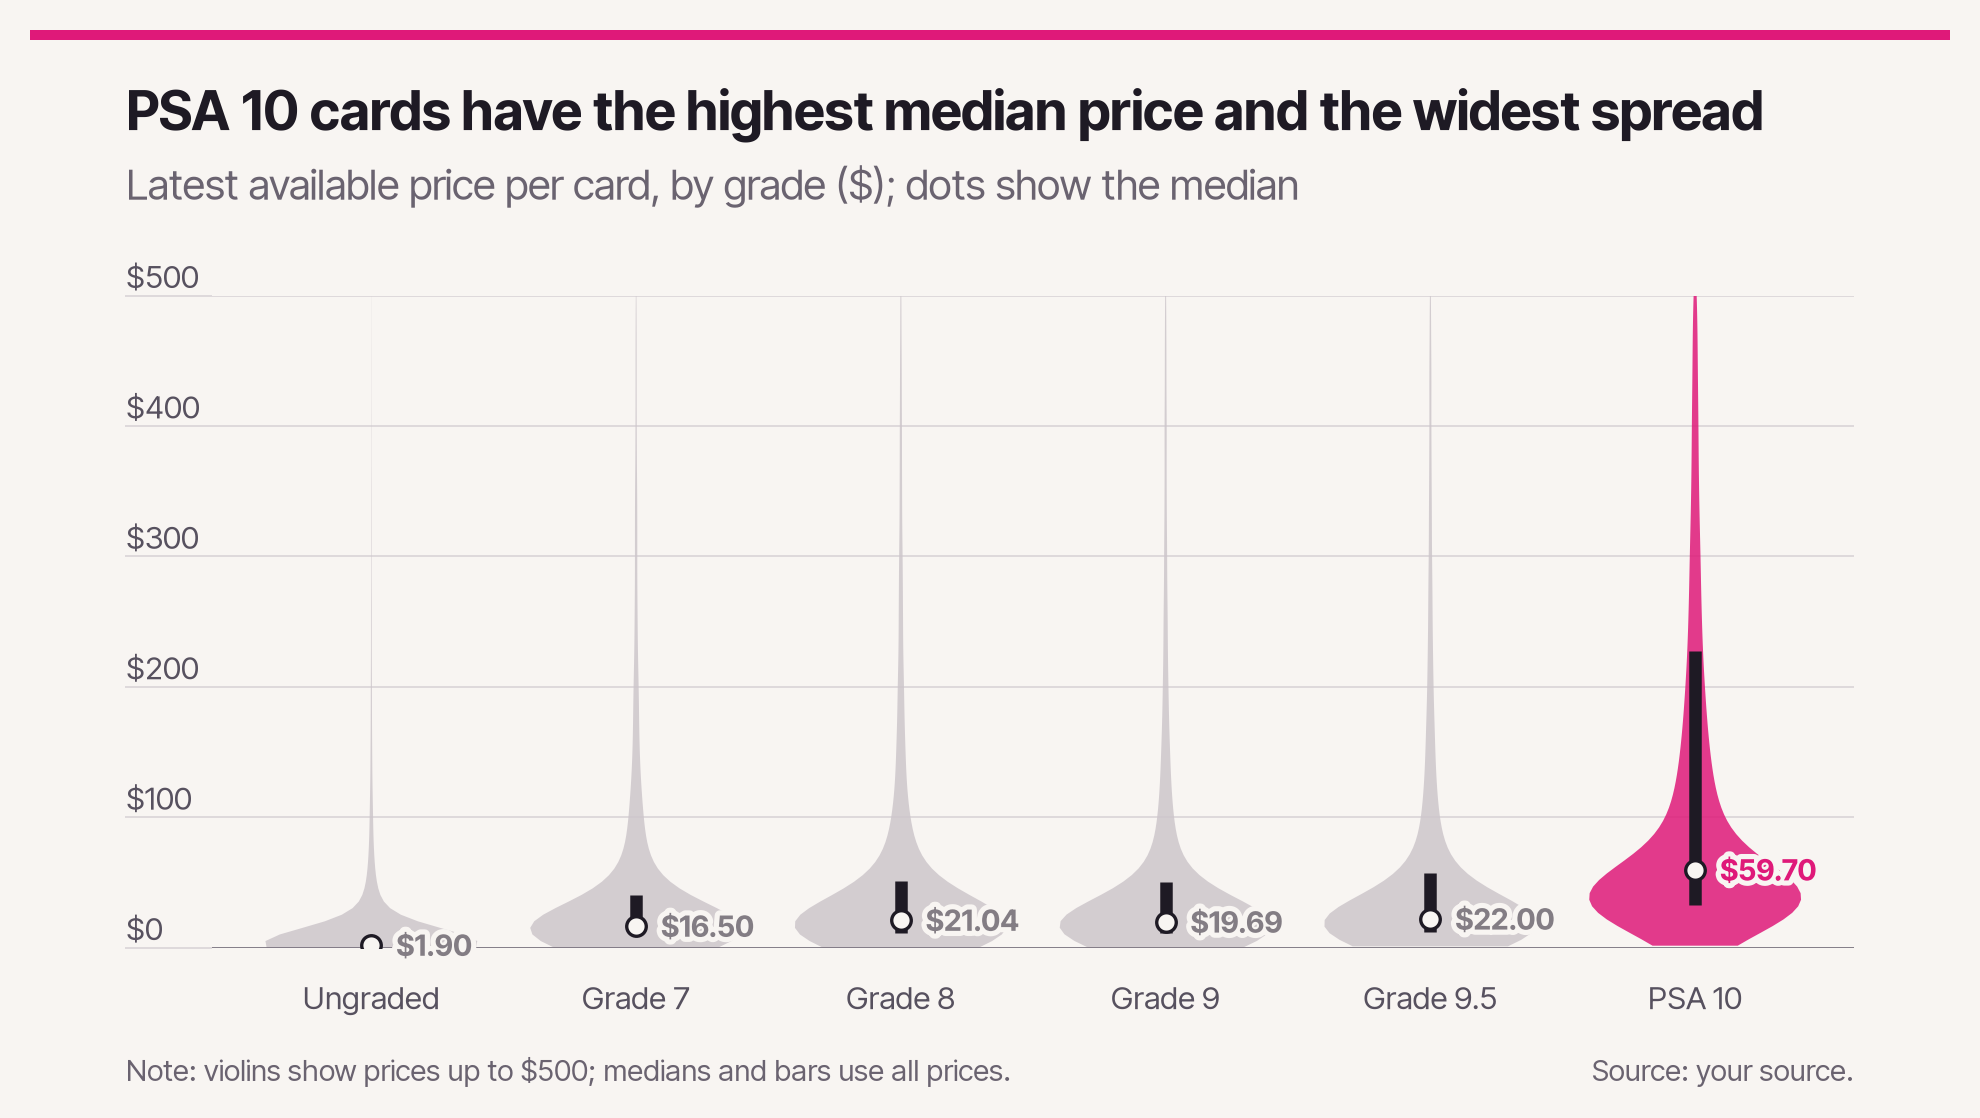

In [59]:
groups = [grade_prices.loc[grade_prices[GROUP] == g, VALUE].to_numpy() for g in order]
capped = [values[values <= price_cap] for values in groups]

fig, ax = cg.chart(title, subtitle, note=note, source=source, grid="y")

parts = ax.violinplot(capped, positions=range(len(order)), widths=0.8, showextrema=False,
                      bw_method=bandwidth)
for body, group_name in zip(parts["bodies"], order):
    body.set_facecolor(colors.get(group_name, cg.NEUTRAL))
    body.set_edgecolor("none")
    body.set_alpha(fill_alpha)
for x, (values, group_name) in enumerate(zip(groups, order)):
    inner(ax, x, values, colors.get(group_name, cg.NEUTRAL))

ax.set_xticks(range(len(order)), order)
ax.set_xlim(-0.6, len(order) - 0.4)
ax.set_ylim(0, price_cap)
cg.number_axis(ax.yaxis, prefix=prefix, suffix=suffix)
cg.baseline(ax)

cg.save(fig, path)
plt.show()


In [ ]:
variant_counts = (
    pokemon_all.groupby("variant")["product_id"]
    .nunique()
    .sort_index(ascending=True)
)

variant_counts

In [ ]:
variant_info = pokemon_all[pokemon_all["variant"] == "Toys R Us Promo"]

variant_info

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, LogLocator

import chartgazing as cg

VALUE, GROUP, NAME = "price", "decade", "set_name"

unit_prefix = "$"
marker_size = 5.5


def swarm(x, diameter):
    """y offsets (same units as x) so dots of the given diameter don't overlap. Greedy, centre-out."""
    order = np.argsort(x)
    ys = np.zeros(len(x))
    placed_x, placed_y = [], []
    for i in order:
        xi = x[i]
        near = [(xj, yj) for xj, yj in zip(placed_x, placed_y) if abs(xj - xi) < diameter]
        candidates = [0.0]
        for xj, yj in near:
            dy = np.sqrt(diameter ** 2 - (xi - xj) ** 2)
            candidates += [yj + dy, yj - dy]
        for c in sorted(candidates, key=abs):
            if all((xi - xj) ** 2 + (c - yj) ** 2 >= diameter ** 2 - 1e-9 for xj, yj in near):
                ys[i] = c
                break
        placed_x.append(xi)
        placed_y.append(ys[i])
    return ys


def set_price_comparison(df, grade="Ungraded", variant="Standard", stat="median"):
    latest = df[
        (df["variant"] == variant) 
        & (df["grade"] == grade)
        & (df["date"] == df["date"].max())
        ]

    set_prices = (
        latest.groupby("set_name", observed=True)
        .agg(price=("price", stat), decade=("decade", "first"))
        .dropna(subset=["decade", "price"])
        .reset_index()
    )
    set_prices["decade"] = set_prices["decade"].astype(int).astype(str) + "s"

    return set_prices.sort_values('price', ascending=False)

def decade_beeswarm(df, title, subtitle, path, highlight=(), note="", source="", pad=1.25):

    order = sorted(df[GROUP].unique(), reverse=True)   # 1990s on top

    fig, ax = cg.chart(title, subtitle, note=note, source=source, grid="x")

    ax.set_xscale("log")
    ax.set_xlim(df[VALUE].min() / pad, df[VALUE].max() * pad)
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5), numticks=100))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{unit_prefix}{x:,g}"))
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_yticks(range(len(order)), order)

    # the swarm is laid out in points, so fit the layout first to know the final axes size
    # on a log axis, distance is measured in log10 units
    cg.fit(fig)
    bbox = ax.get_window_extent()
    pt = 72 / fig.dpi
    x_per_pt = np.diff(np.log10(ax.get_xlim()))[0] / (bbox.width * pt)
    y_per_pt = np.diff(ax.get_ylim())[0] / (bbox.height * pt)

    for yi, group_name in enumerate(order):
        group = df[df[GROUP] == group_name]
        offsets = swarm(np.log10(group[VALUE].to_numpy()) / x_per_pt, marker_size * 1.05) * y_per_pt
        is_hl = group[NAME].isin(highlight).to_numpy()

        ax.scatter(group[VALUE][~is_hl], yi + offsets[~is_hl], s=marker_size ** 2,
                color=cg.SECONDARY, alpha=0.75, linewidth=0, clip_on=False)
        ax.scatter(group[VALUE][is_hl], yi + offsets[is_hl], s=(marker_size * 1.3) ** 2,
                color=cg.PRIMARY, edgecolor=cg.BACKGROUND, linewidth=0.6, zorder=3, clip_on=False)

        for name, xv, yo in zip(group[NAME][is_hl], group[VALUE][is_hl], offsets[is_hl]):
            ax.annotate(name, xy=(xv, yi + yo), xytext=(0, 6), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7.5, fontweight="bold", color=cg.TEXT)

    cg.save(fig, path)
    plt.show()



In [ ]:
set_prices = set_price_comparison(pokemon_all, stat="max")


title = "Ungraded: Max"
subtitle = "Standard: Any"
path = "images/beeswarm_test.png"
source = "Source: Test source."
note = "Note: Test note."

decade_beeswarm(set_prices, title, subtitle, path, highlight=(), note=note, source=source)

In [ ]:
set_prices = set_price_comparison(pokemon_all, stat="max")


title = "Ungraded: Max"
subtitle = "Standard: Any"
path = "images/beeswarm_test.png"
source = "Source: Test source."
note = "Note: Test note."

decade_beeswarm(set_prices, title, subtitle, path, highlight=(), note=note, source=source)